# ECE 3715 Mini-Project 1

## Probability, Bayes, and Discrete Random Variables

This notebook builds a packet-error model in eight steps. The main chain of ideas is:

1. A bit error is a Bernoulli event.
2. The number of errors in a packet is Binomial.
3. A clean packet is a geometric "success" for the retransmission process.
4. The clean-packet probability determines both expected transmissions and goodput.

The code uses one seeded parent generator and one independent child generator per step so that rerunning one section does not change later sections.

In [43]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

from mp1lib import bsc

SEED = 19 
rng = np.random.default_rng(SEED)

# Independent generator for each step

rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]
rng_bonusA = rng.spawn(1)[0]
rng_bonusB = rng.spawn(1)[0]

test_rng = rng.spawn(1)[0]

test_bits = np.array([0, 1, 1, 0])
test_result = bsc(test_bits, p=0, rng=test_rng)

assert np.array_equal(test_result, test_bits)

print("Setup completed.")
print("bsc test passed.")

Setup completed.
bsc test passed.


## Step 1: The Sample Space and Probability Axioms

For a four-bit packet, each bit has two possible error states:

- $0$: the bit is correct
- $1$: the bit is corrupted

Therefore, the total number of possible error patterns is

$$
2^4 = 16
$$

If a pattern contains $k$ errors, it contains $4-k$ correct bits.
Since the bit errors are independent, the exact probability of that
pattern is

$$
P(\text{pattern}) = p^k(1-p)^{4-k}
$$

where $p=0.1$.

In [44]:
#1) Enumerate all 16 patterns and confirm the sum is 1
p = 0.1

# Generate the numbers 0 through 15
pattern_numbers = np.arange(16)

# Convert each number into a four-bit binary error pattern
patterns = (
    (pattern_numbers[:, None] >> np.arange(3, -1, -1)) & 1
)

# Count the number of errors in each pattern
error_counts = patterns.sum(axis=1)

# Calculate the exact probability of each pattern
exact_pattern_prob = (
    p**error_counts
    * (1 - p)**(4 - error_counts)
)

print(f"{'Pattern':<10} {'Errors':<10} {'Probability':<15}")
print("-" * 35)

for pattern, errors, probability in zip(
    patterns,
    error_counts,
    exact_pattern_prob
):
    pattern_text = "".join(str(bit) for bit in pattern)

    print(
        f"{pattern_text:<10}"
        f"{errors:<10}"
        f"{probability:<15.6f}"
    )

print("-" * 35)
print(f"Sum = {exact_pattern_prob.sum():.10f}")

Pattern    Errors     Probability    
-----------------------------------
0000      0         0.656100       
0001      1         0.072900       
0010      1         0.072900       
0011      2         0.008100       
0100      1         0.072900       
0101      2         0.008100       
0110      2         0.008100       
0111      3         0.000900       
1000      1         0.072900       
1001      2         0.008100       
1010      2         0.008100       
1011      3         0.000900       
1100      2         0.008100       
1101      3         0.000900       
1110      3         0.000900       
1111      4         0.000100       
-----------------------------------
Sum = 1.0000000000


### 2) Compute by hand


The events are:

- $A$: at least one error among the first two bits
- $B$: exactly two errors in the four-bit packet
- $C$: the fourth bit is in error

#### Event A

Event $A$ does not occur when both of the first two bits are correct.
The probability that both are correct is

$$
P(A^c)=(0.9)(0.9)=0.81
$$

Therefore,

$$
P(A)=1-P(A^c)
$$

$$
P(A)=1-0.81=0.19
$$

#### Event B

Event $B$ requires exactly two errors among four bits. The number of
ways to select two error positions from four positions is

$$
\binom{4}{2}=6
$$

Therefore,

$$
P(B)=\binom{4}{2}(0.1)^2(0.9)^2
$$

$$
P(B)=6(0.01)(0.81)=0.0486
$$

#### Event C

Event $C$ occurs when the fourth bit is corrupted. Every individual
bit has an error probability of $0.1$. Therefore,

$$
P(C)=0.1
$$

In [45]:
# A: at least one of the first two bits has an error
A_exact = (patterns[:, 0] == 1) | (patterns[:, 1] == 1)

# B: exactly two errors in the four-bit packet
B_exact = error_counts == 2

# C: the fourth bit has an error
C_exact = patterns[:, 3] == 1

# Add the probabilities of the patterns belonging to each event
P_A = exact_pattern_prob[A_exact].sum()
P_B = exact_pattern_prob[B_exact].sum()
P_C = exact_pattern_prob[C_exact].sum()

print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(C) = {P_C:.4f}")

P(A) = 0.1900
P(B) = 0.0486
P(C) = 0.1000


In [46]:
#3) Estimate using Monte Carlo simulation with N = 10^6 packets

N = 1_000_000

# create one million transmitted packets containing four correct bits
transmitted_bits = np.zeros((N, 4), dtype=np.uint8)

# pass all packets through the binary symmetric channel
simulated_patterns = bsc(
    transmitted_bits,
    p=0.1,
    rng=rng_step1
)

# Count the number of errors in each packet
simulated_error_counts = simulated_patterns.sum(axis=1)

# define the simulated events
A_sim = (
    (simulated_patterns[:, 0] == 1)
    | (simulated_patterns[:, 1] == 1)
)

B_sim = simulated_error_counts == 2

C_sim = simulated_patterns[:, 3] == 1

# estimate each probability
P_A_mc = A_sim.mean()
P_B_mc = B_sim.mean()
P_C_mc = C_sim.mean()

print(f"P(A): exact = {P_A:.6f}, mc_estimate = {P_A_mc:.6f}")
print(f"P(B): exact = {P_B:.6f}, mc_estimate = {P_B_mc:.6f}")
print(f"P(C): exact = {P_C:.6f}, mc_estimate = {P_C_mc:.6f}")

P(A): exact = 0.190000, mc_estimate = 0.189813
P(B): exact = 0.048600, mc_estimate = 0.048407
P(C): exact = 0.100000, mc_estimate = 0.099706


### 4) Exact intersections

The symbol $\cap$ means “and.”

For $A\cap B$, there are five valid patterns with exactly two errors:

$$
P(A\cap B)=5(0.1)^2(0.9)^2=0.0405.
$$

Because $A$ concerns the first two bits and $C$ concerns the fourth bit,

$$
P(A\cap C)=P(A)P(C)=(0.19)(0.1)=0.0190.
$$

For $B\cap C$, the fourth bit is an error and one of the first three
bits is an error:

$$
P(B\cap C)=3(0.1)^2(0.9)^2=0.0243.
$$

For $A\cap B\cap C$, the fourth bit is an error and the other error
must be in bit 1 or bit 2:

$$
P(A\cap B\cap C)=2(0.1)^2(0.9)^2=0.0162.
$$

In [47]:
#4) Compute the three pairwise intersections and the triple intersections, exactly and empirically
P_AB = exact_pattern_prob[A_exact & B_exact].sum()
P_AC = exact_pattern_prob[A_exact & C_exact].sum()
P_BC = exact_pattern_prob[B_exact & C_exact].sum()
P_ABC = exact_pattern_prob[A_exact & B_exact & C_exact].sum()

# Monte Carlo estimates
P_AB_mc = (A_sim & B_sim).mean()
P_AC_mc = (A_sim & C_sim).mean()
P_BC_mc = (B_sim & C_sim).mean()
P_ABC_mc = (A_sim & B_sim & C_sim).mean()

print(f"P(A and B): exact = {P_AB:.6f}, mc_estimate = {P_AB_mc:.6f}")
print(f"P(A and C): exact = {P_AC:.6f}, mc_estimate = {P_AC_mc:.6f}")
print(f"P(B and C): exact = {P_BC:.6f}, mc_estimate = {P_BC_mc:.6f}")
print(f"P(A, B, and C): exact = {P_ABC:.6f}, mc_estimate = {P_ABC_mc:.6f}")

P(A and B): exact = 0.040500, mc_estimate = 0.040334
P(A and C): exact = 0.019000, mc_estimate = 0.019070
P(B and C): exact = 0.024300, mc_estimate = 0.024290
P(A, B, and C): exact = 0.016200, mc_estimate = 0.016217


In [48]:
### 5)Inclusion-Exclusion

# Exact union using inclusion-exclusion
P_union = (
    P_A
    + P_B
    + P_C
    - P_AB
    - P_AC
    - P_BC
    + P_ABC
)
# Monte Carlo estimate calculated directly
P_union_mc = (A_sim | B_sim | C_sim).mean()

print(f"Exact P(A or B or C) = {P_union:.6f}")
print(f"MC estimate           = {P_union_mc:.6f}")
print(f"Absolute difference   = {abs(P_union_mc - P_union):.6e}")

Exact P(A or B or C) = 0.271000
MC estimate           = 0.270449
Absolute difference   = 5.510000e-04


### 6) Standard error and the three-standard-error check

For an event with true probability $P$ estimated from $N$ independent packets, the Monte Carlo estimate is a sample proportion with standard error

$$
\operatorname{SE}(\widehat P)=\sqrt{\frac{P(1-P)}{N}}.
$$

The tables below compare every absolute error, $|\widehat P-P|$, with $3\operatorname{SE}(\widehat P)$. A result inside three standard errors is consistent with ordinary sampling variation; it is evidence of agreement, not proof that the simulation is exact.

In [49]:
#6)State the standard error of a probability estimate at N = 10^6 
#and confirm every difference above sits within three standard errors. 

event_names = [
    "A",
    "B",
    "C",
    "A and B",
    "A and C",
    "B and C",
    "A and B and C"
]

exact_values = np.array([
    P_A,
    P_B,
    P_C,
    P_AB,
    P_AC,
    P_BC,
    P_ABC
])

mc_values = np.array([
    P_A_mc,
    P_B_mc,
    P_C_mc,
    P_AB_mc,
    P_AC_mc,
    P_BC_mc,
    P_ABC_mc
])

differences = np.abs(mc_values - exact_values)

standard_errors = np.sqrt(
    exact_values * (1 - exact_values) / N
)

within_three_se = differences <= 3 * standard_errors

print(
    f"{'Event':<16}"
    f"{'Exact':>12}"
    f"{'MC estimate':>15}"
    f"{'Difference':>15}"
    f"{'Std. error':>15}"
    f"{'Within 3 SE':>15}"
)

print("-" * 88)

for name, exact, mc, difference, se, within in zip(
    event_names,
    exact_values,
    mc_values,
    differences,
    standard_errors,
    within_three_se
):
    print(
        f"{name:<16}"
        f"{exact:>12.6f}"
        f"{mc:>15.6f}"
        f"{difference:>15.6e}"
        f"{se:>15.6e}"
        f"{str(within):>15}"
    )

Event                  Exact    MC estimate     Difference     Std. error    Within 3 SE
----------------------------------------------------------------------------------------
A                   0.190000       0.189813   1.870000e-04   3.923009e-04           True
B                   0.048600       0.048407   1.930000e-04   2.150303e-04           True
C                   0.100000       0.099706   2.940000e-04   3.000000e-04           True
A and B             0.040500       0.040334   1.660000e-04   1.971288e-04           True
A and C             0.019000       0.019070   7.000000e-05   1.365247e-04           True
B and C             0.024300       0.024290   1.000000e-05   1.539789e-04           True
A and B and C       0.016200       0.016217   1.700000e-05   1.262440e-04           True


In [50]:
#Union

union_difference = abs(P_union_mc - P_union)

union_se = np.sqrt(
    P_union * (1 - P_union) / N
)

union_within_three_se = union_difference <= 3 * union_se

print(f"Union exact:             {P_union:.6f}")
print(f"Union MC estimate:       {P_union_mc:.6f}")
print(f"Union difference:        {union_difference:.6e}")
print(f"Union standard error:    {union_se:.6e}")
print(f"Three standard errors:   {3 * union_se:.6e}")
print(f"Union within three SE:   {union_within_three_se}")

Union exact:             0.271000
Union MC estimate:       0.270449
Union difference:        5.510000e-04
Union standard error:    4.444761e-04
Three standard errors:   1.333428e-03
Union within three SE:   True


All seven event estimates and the union estimate were within three standard errors of their exact probabilities. These results are consistent with the theoretical model and expected sampling variation.

## Figure 1 Plot

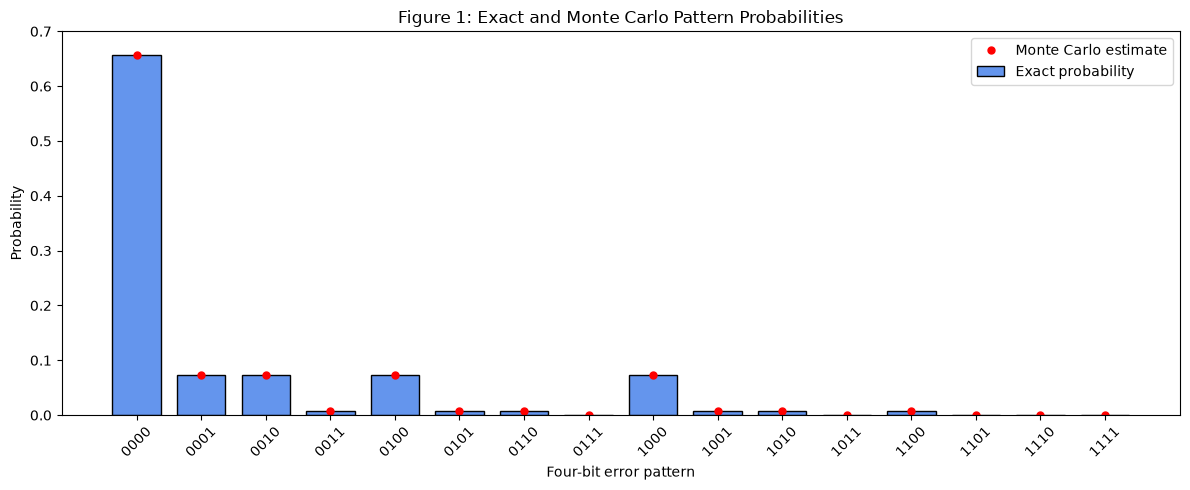

Exact probability sum: 0.9999999999999999
Monte Carlo probability sum: 1.0


In [51]:
# Convert each simulated four-bit pattern into a number from 0 to 15
binary_weights = np.array([8, 4, 2, 1])

simulated_pattern_numbers = (
    simulated_patterns @ binary_weights
)

# Count how many times each pattern appeared
simulated_pattern_counts = np.bincount(
    simulated_pattern_numbers,
    minlength=16
)

# Convert counts into Monte Carlo probability estimates
mc_pattern_prob = simulated_pattern_counts / N

# Create labels: 0000, 0001, ..., 1111
pattern_labels = [
    "".join(str(bit) for bit in pattern)
    for pattern in patterns
]

x = np.arange(16)

plt.figure(figsize=(12, 5))

# Exact probabilities as bars
plt.bar(
    x,
    exact_pattern_prob,
    width=0.75,
    color="cornflowerblue",
    edgecolor="black",
    label="Exact probability"
)

# Monte Carlo estimates as red dots
plt.plot(
    x,
    mc_pattern_prob,
    "ro",
    markersize=5,
    label="Monte Carlo estimate"
)

plt.xticks(x, pattern_labels, rotation=45)
plt.xlabel("Four-bit error pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo Pattern Probabilities")
plt.legend()
plt.tight_layout()
plt.ylim(0, 0.70)
plt.show()

#Verigy both sets add to 1
print("Exact probability sum:", exact_pattern_prob.sum())
print("Monte Carlo probability sum:", mc_pattern_prob.sum())

### Figure 1 interpretation

The pattern `0000` means that none of the four bits was corrupted. Its exact probability is

$$
(0.9)^4=0.6561,
$$

so it is the most likely pattern. Patterns with the same number of errors have equal probabilities because all four bits have the same independent error probability. The Monte Carlo markers nearly overlap the exact bars; the numerical table above checks that each event-level difference is within three standard errors.

## Step 2: Conditional probability and Bayes

### 1) Conditional probabilities, prior, and posterior

Let $E$ mean that a bit is actually in error, and let $F$
mean that the circuit raises a flag. The event $E^c$ means
that the bit has no error.

The circuit's conditional probabilities are:

$$
P(F\mid E)=0.95,
\qquad
P(F\mid E^c)=0.02.
$$

The prior probability of an error is:

$$
P(E)=p,
\qquad
P(E^c)=1-p.
$$

A flag can occur on an erroneous bit or on a correct bit.
Using the law of total probability:

$$
P(F)
= P(F\mid E)P(E)+P(F\mid E^c)P(E^c)
=0.95p+0.02(1-p).
$$

Bayes' rule gives the probability that a flagged bit is
actually in error:

$$
P(E\mid F)
=\frac{P(F\mid E)P(E)}{P(F)}
=\frac{0.95p}{0.95p+0.02(1-p)}
=\frac{0.95p}{0.02+0.93p}.
$$

### 2) Evaluate the posterior at three prior probabilities

In [52]:
# Bayes formula
def posterior_error(p):
    top = 0.95 * p
    bottom = 0.95 * p + 0.02 * (1 - p)
    return top / bottom

# Check the three probabilities

p_values = [0.1, 0.01, 0.001]

for p_value in p_values:
    answer = posterior_error(p_value)
    print("p =", p_value, "posterior =", round(answer, 6))

p = 0.1 posterior = 0.840708
p = 0.01 posterior = 0.324232
p = 0.001 posterior = 0.045389


### 3-4) Posterior curve and crossover probability

At the crossover, the posterior probability equals 0.5:

$$
\frac{0.95p}{0.95p+0.02(1-p)}=0.5.
$$

This means that true flags and false alarms are equally likely:

$$
0.95p=0.02(1-p).
$$

Expanding and collecting the terms containing p:

$$
0.95p=0.02-0.02p
$$

$$
0.97p=0.02
$$

$$
p=\frac{0.02}{0.97}=0.02061856\ldots
$$

To three significant figures, the crossover is:

$$
\boxed{p=0.0206}.
$$

In [53]:
# Calculate the crossover
p_cross = 0.02 / 0.97

print("Crossover p =", round(p_cross, 4))
print("Posterior =", round(posterior_error(p_cross), 6))

Crossover p = 0.0206
Posterior = 0.5


In [54]:
# 5) Monte Carlo check
N_step2 = 10_000_000

# Decide which bits actually have errors
errors = rng_step2.random(N_step2) < p_cross

# The circuit flags errors with probability 0.95
# and correct bits with probability 0.02
flag_probs = np.where(errors, 0.95, 0.02)
flags = rng_step2.random(N_step2) < flag_probs

# Count all flags and the flags on erroneous bits
flag_count = flags.sum()
error_flag_count = (errors & flags).sum()

# Estimate the posterior and its standard error
posterior_mc = error_flag_count / flag_count
posterior_se = np.sqrt(
    posterior_mc * (1 - posterior_mc) / flag_count
)

print("Number of flags =", flag_count)
print("Flagged bits with errors =", error_flag_count)
print("Exact posterior =", round(posterior_error(p_cross), 6))
print("Monte Carlo posterior =", round(posterior_mc, 6))
print("Absolute difference =", round(abs(posterior_mc - posterior_error(p_cross)), 6))
print("Standard error =", round(posterior_se, 6))

Number of flags = 392009
Flagged bits with errors = 196375
Exact posterior = 0.5
Monte Carlo posterior = 0.500945
Absolute difference = 0.000945
Standard error = 0.000799


### Figure 2: Plot the posterior versus the prior

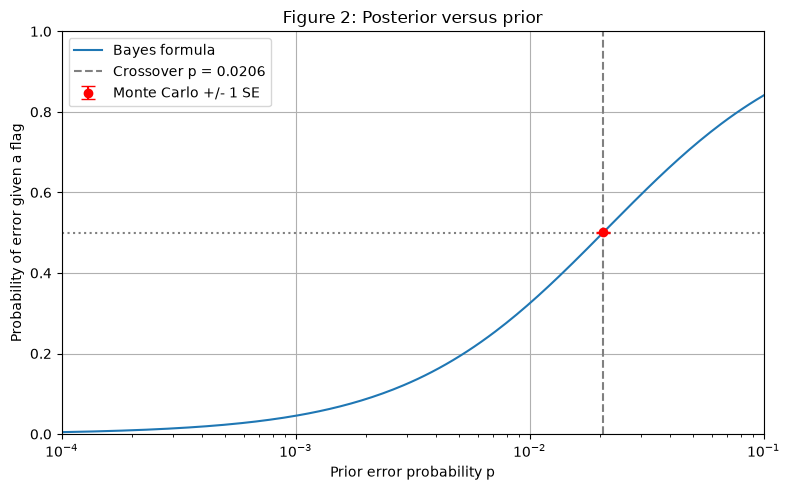

In [55]:
# Make 200 logarithmically spaced prior probabilities
p_plot = np.logspace(-4, -1, 200)
posterior_plot = posterior_error(p_plot)

plt.figure(figsize=(8, 5))

# Exact posterior curve
plt.plot(p_plot, posterior_plot, label="Bayes formula")

# Mark the crossover
plt.axvline(
    p_cross, color="gray", linestyle="--",
    label="Crossover p = 0.0206"
)
plt.axhline(0.5, color="gray", linestyle=":")

# Monte Carlo point with a standard-error bar
plt.errorbar(
    p_cross, posterior_mc, yerr=posterior_se,
    fmt="ro", capsize=5, label="Monte Carlo +/- 1 SE"
)

plt.xscale("log")
plt.xlim(0.0001, 0.1)
plt.ylim(0, 1)
plt.xlabel("Prior error probability p")
plt.ylabel("Probability of error given a flag")
plt.title("Figure 2: Posterior versus prior")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Figure 2 interpretation

As the prior error probability $p$ increases, a flag is more likely to indicate a real error. The posterior reaches 0.5 at $p\approx0.0206$, where true-error flags and false-positive flags are equally likely. The Monte Carlo point lies near the analytic curve; the printed absolute difference can be compared directly with the reported standard error.

### 6) Explanation for a manager

The circuit catches 95% of real errors, but it also flags 2%
of correct bits. On a good link, there are many more correct
bits than erroneous bits, so most flags are false alarms.
For p = 0.001, only about 4.54% of flagged bits actually
have errors.

## Step 3: Independence

### 1) Two fair coins

The possible outcomes are HH, HT, TH, and TT.
Each outcome has probability 1/4.

- E1: The first coin is heads.
- E2: The second coin is heads.
- E3: The two coins match.

Each event has probability 1/2.

Each pair happens together only for HH, so:

$$
P(E_1 \cap E_2) = P(E_1 \cap E_3)
= P(E_2 \cap E_3) = \frac14.
$$

The product of the probabilities for each pair is also:

$$
\frac12 \times \frac12 = \frac14.
$$

Therefore, the events are pairwise independent.

However, all three events happen together only for HH:

$$
P(E_1 \cap E_2 \cap E_3) = \frac14.
$$

The product of all three probabilities is:

$$
P(E_1)P(E_2)P(E_3) = \frac18.
$$

Since 1/4 does not equal 1/8, the events are not mutually
independent.

In [56]:
N_step3 = 1_000_000

# 1 means heads, 0 means tails
coin1 = rng_step3.integers(0, 2, size=N_step3)
coin2 = rng_step3.integers(0, 2, size=N_step3)

# Define the three events
E1 = coin1 == 1
E2 = coin2 == 1
E3 = coin1 == coin2

p1, p2, p3 = E1.mean(), E2.mean(), E3.mean()

comparisons = [
    ("E1 and E2", p1 * p2, (E1 & E2).mean()),
    ("E1 and E3", p1 * p3, (E1 & E3).mean()),
    ("E2 and E3", p2 * p3, (E2 & E3).mean()),
    ("E1, E2, E3", p1 * p2 * p3, (E1 & E2 & E3).mean()),
]

print("Events          Product      Joint       Difference   Joint SE")
print("----------------------------------------------------------------")
for name, product, joint in comparisons:
    joint_se = np.sqrt(joint * (1 - joint) / N_step3)
    print(
        f"{name:<15} {product:<12.6f} {joint:<11.6f} "
        f"{abs(product - joint):<12.6f} {joint_se:.6f}"
    )

Events          Product      Joint       Difference   Joint SE
----------------------------------------------------------------
E1 and E2       0.250216     0.250446    0.000230     0.000433
E1 and E3       0.250456     0.250446    0.000010     0.000433
E2 and E3       0.250220     0.250446    0.000226     0.000433
E1, E2, E3      0.125223     0.250446    0.125223     0.000433


### 2) Two receivers observing the same bit

The transmitted bit is equally likely to be 0 or 1.
Receiver 1 has an error probability of 0.1, and receiver 2
has an error probability of 0.3.

We compare the receiver outputs for all transmissions,
then separately when the transmitted bit was 0 or 1.

In [57]:
# Simulate one million transmissions
sent_bits = rng_step3.integers(0, 2, size=N_step3)

receiver1 = bsc(sent_bits, p=0.1, rng=rng_step3)
receiver2 = bsc(sent_bits, p=0.3, rng=rng_step3)

# Calculate correlation and an approximate standard error
def corr_with_se(bits1, bits2):
    corr = np.corrcoef(bits1, bits2)[0, 1]

    # Split the samples into 100 groups
    groups1 = np.array_split(bits1, 100)
    groups2 = np.array_split(bits2, 100)

    group_corr = []

    for group1, group2 in zip(groups1, groups2):
        answer = np.corrcoef(group1, group2)[0, 1]
        group_corr.append(answer)

    # Use the variation between groups to estimate the SE
    se = np.std(group_corr, ddof=1) / np.sqrt(100)

    return corr, se

# Select the two groups of transmitted bits
sent0 = sent_bits == 0
sent1 = sent_bits == 1

# Calculate the three correlations
corr_all, se_all = corr_with_se(receiver1, receiver2)

corr0, se0 = corr_with_se(
    receiver1[sent0], receiver2[sent0]
)

corr1, se1 = corr_with_se(
    receiver1[sent1], receiver2[sent1]
)

# Print the results
print("Group          Samples      Correlation     Std. error")
print(f"All bits       {N_step3:7d}      {corr_all:.6f}        {se_all:.6f}")
print(f"Sent bit = 0   {sent0.sum():7d}      {corr0:.6f}        {se0:.6f}")
print(f"Sent bit = 1   {sent1.sum():7d}      {corr1:.6f}        {se1:.6f}")

Group          Samples      Correlation     Std. error
All bits       1000000      0.319142        0.000926
Sent bit = 0    500245      -0.000579        0.001386
Sent bit = 1    499755      0.000623        0.001422


### Receiver-correlation results

The unconditional receiver outputs have a clear positive correlation because both contain information about the same randomly changing transmitted bit. After conditioning on the transmitted bit being 0 or 1, that shared cause is fixed; the remaining randomness comes only from the two independent channels, so the conditional correlations should be zero. The printed standard errors show whether the small simulated conditional correlations are distinguishable from zero.

### 3) Effect on a sensor system

When two sensors share a common cause, treating their readings as independent can count the same information twice and make the system too confident in its decision.

## Step 4: Bernoulli trials and the Binomial

### 1) Why the error count is Binomial

Each of the 1000 bits either has an error or does not, with
the same error probability p. Assuming the bit errors are
independent, the total number of errors follows a Binomial
distribution with n = 1000.

$$
X \sim \operatorname{Binomial}(1000, p).
$$

In [58]:
from mp1lib import packet_errors
from scipy.stats import binom

# With p = 0, all three packets should have zero errors
test_counts = packet_errors(
    n_pkt=3, n_bits=4, p=0, rng=test_rng
)

assert np.array_equal(test_counts, np.array([0, 0, 0]))

print("Test error counts:", test_counts)
print("packet_errors test passed.")

Test error counts: [0 0 0]
packet_errors test passed.


### 2) Simulate packet errors and plot the distribution

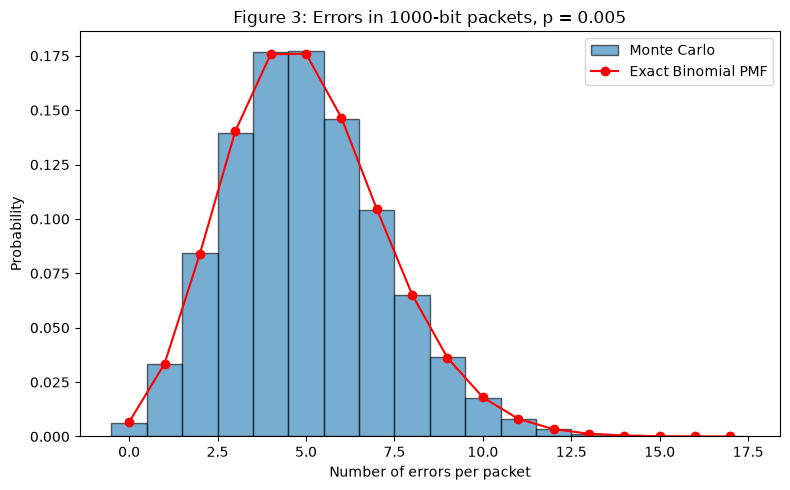

In [59]:
# Simulate 100,000 packets containing 1000 bits each
N_packets = 100_000
n_bits = 1000
p_step4 = 0.005

error_counts = packet_errors(
    N_packets, n_bits, p_step4, rng_step4
)

# Calculate the exact Binomial probabilities
k = np.arange(error_counts.max() + 1)
exact_pmf = binom.pmf(k, n_bits, p_step4)

# Give each integer error count its own histogram bin
bins = np.arange(-0.5, error_counts.max() + 1.5, 1)

plt.figure(figsize=(8, 5))

plt.hist(
    error_counts,
    bins=bins,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Monte Carlo"
)

plt.plot(k, exact_pmf, "ro-", label="Exact Binomial PMF")

plt.xlabel("Number of errors per packet")
plt.ylabel("Probability")
plt.title("Figure 3: Errors in 1000-bit packets, p = 0.005")
plt.legend()
plt.tight_layout()
plt.show()

### Figure 3 interpretation

The histogram is centered near five errors, which agrees with the Binomial mean $np=5$. Its spread also agrees with the theoretical variance $np(1-p)=4.975$. The close overlap between the histogram and the exact PMF supports the model: each packet error count is the sum of 1000 independent Bernoulli error indicators.

### 3) Compare the mean and variance

For a Binomial distribution, the theoretical mean and variance are

$$
E[X]=np=1000(0.005)=5,
$$

$$
\operatorname{Var}(X)=np(1-p)=1000(0.005)(0.995)=4.975.
$$

In [60]:
# Calculate the sample mean and sample variance
sample_mean = error_counts.mean()
sample_var = error_counts.var(ddof=1)

# Calculate the theoretical values
exact_mean = n_bits * p_step4
exact_var = n_bits * p_step4 * (1 - p_step4)

# Standard error of the sample mean
mean_se = np.sqrt(exact_var / N_packets)

# Estimate the variance standard error using 100 groups
groups = np.array_split(error_counts, 100)
group_vars = []

for group in groups:
    group_vars.append(group.var(ddof=1))

var_se = np.std(group_vars, ddof=1) / np.sqrt(100)

# Print the comparisons
print("Quantity       Exact         Simulation      Difference      Std. error")
print(f"Mean           {exact_mean:.6f}      {sample_mean:.6f}        {abs(sample_mean - exact_mean):.6f}        {mean_se:.6f}")
print(f"Variance       {exact_var:.6f}      {sample_var:.6f}        {abs(sample_var - exact_var):.6f}        {var_se:.6f}")

Quantity       Exact         Simulation      Difference      Std. error
Mean           5.000000      4.998380        0.001620        0.007053
Variance       4.975000      4.957707        0.017293        0.022292


### 4) Probability of a clean packet

A packet is clean when all 1000 bits have no errors.
Since the bit errors are independent:

$$
P(X = 0) = (1-p)^{1000}.
$$

In [61]:
p_values_step4 = [0.005, 0.001, 0.0001]

print("p        Exact       Monte Carlo    Difference     Std. error")

for p_value in p_values_step4:
    # Simulate packets at this error probability
    counts = packet_errors(
        N_packets, n_bits, p_value, rng_step4
    )

    # Calculate exact and simulated clean probabilities
    exact_clean = (1 - p_value) ** n_bits
    mc_clean = (counts == 0).mean()

    difference = abs(mc_clean - exact_clean)

    clean_se = np.sqrt(
        exact_clean * (1 - exact_clean) / N_packets
    )

    print(
        f"{p_value:<9.4f}"
        f"{exact_clean:<12.6f}"
        f"{mc_clean:<15.6f}"
        f"{difference:<15.6f}"
        f"{clean_se:.6f}"
    )

p        Exact       Monte Carlo    Difference     Std. error
0.0050   0.006654    0.006430       0.000224       0.000257
0.0010   0.367695    0.368580       0.000885       0.001525
0.0001   0.904833    0.903640       0.001193       0.000928


## Step 5: The Poisson Approximation

For a 1000-bit packet, the number of bit errors follows

$$
X \sim \operatorname{Binomial}(n,p),
$$

where

$$
n = 1000.
$$

When $n$ is large and $p$ is small, the Binomial distribution can be approximated by a Poisson distribution with

$$
\lambda = np.
$$

Therefore, we compare

$$
X \sim \operatorname{Binomial}(1000,p)
$$

with

$$
Y \sim \operatorname{Poisson}(1000p).
$$

The total variation distance between the two probability mass functions is

$$
d_{TV} = \frac{1}{2}\sum_k |P_X(k)-P_Y(k)|.
$$

In [62]:
# Hand-checkable tests for tv_distance()
from mp1lib import tv_distance

same1 = np.array([0.2, 0.3, 0.5])
same2 = np.array([0.2, 0.3, 0.5])
disjoint1 = np.array([1.0, 0.0])
disjoint2 = np.array([0.0, 1.0])

assert tv_distance(same1, same2) == 0.0
assert tv_distance(disjoint1, disjoint2) == 1.0

print("tv_distance tests passed.")

tv_distance tests passed.


In [63]:
from scipy.stats import binom, poisson
from mp1lib import tv_distance

# Step 5 parameters
n = 1000
p_values = [0.5, 0.05, 0.005, 0.001, 0.0005]

tv_results = []

print("p          lambda       Total variation    Poisson tail")
print("-------------------------------------------------------")

for p in p_values:
    lam = n * p

    k_max = int(max(
        binom.ppf(1 - 1e-12, n, p),
        poisson.ppf(1 - 1e-12, lam)
    ))

    poisson_tail = 1 - poisson.cdf(k_max, lam)

    k = np.arange(0, k_max + 1)

    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)

    binom_pmf = np.append(binom_pmf, 1 - binom_pmf.sum())
    poisson_pmf = np.append(poisson_pmf, 1 - poisson_pmf.sum())

    d_tv = tv_distance(binom_pmf, poisson_pmf)
    tv_results.append(d_tv)

    print(
        f"{p:<10g} {lam:<12g} "
        f"{d_tv:<18.6f} {poisson_tail:.2e}"
    )

p          lambda       Total variation    Poisson tail
-------------------------------------------------------
0.5        500          0.166057           9.08e-13
0.05       50           0.012446           8.24e-13
0.005      5            0.001228           9.93e-13
0.001      1            0.000276           3.00e-13
0.0005     0.5          0.000114           3.22e-13


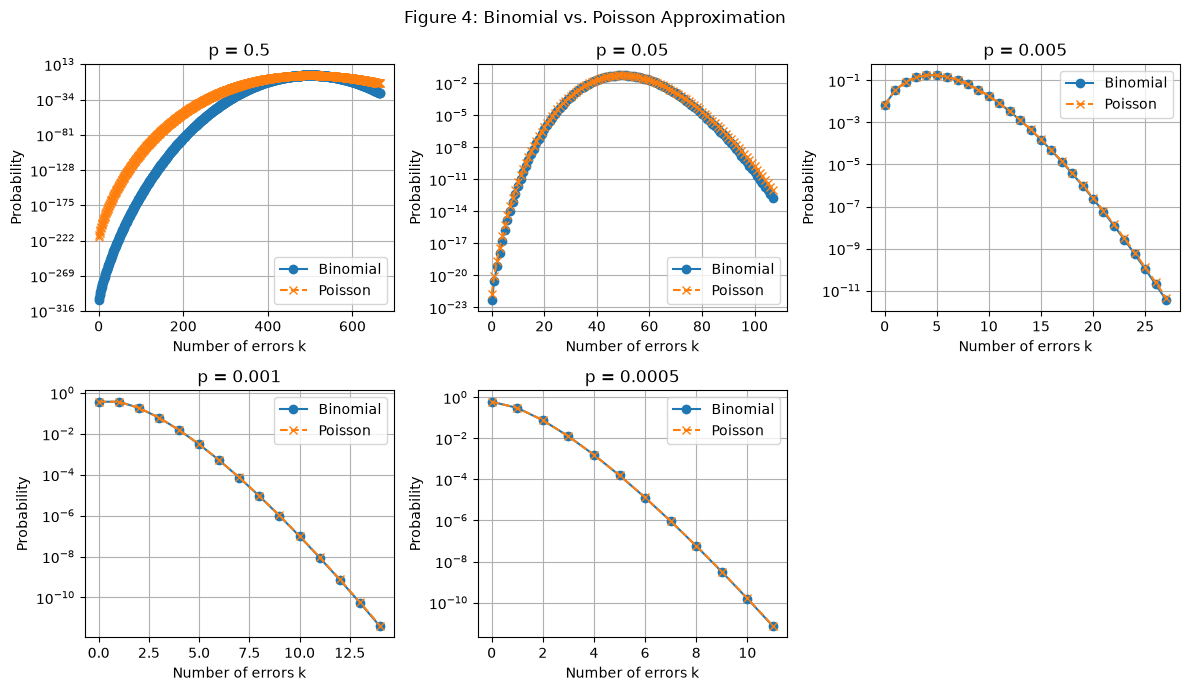

In [64]:
import numpy as np
import matplotlib.pyplot as plt
# Figure 4: Binomial vs. Poisson PMFs

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for i, p in enumerate(p_values):
    lam = n * p

    k_max = int(max(
        binom.ppf(1 - 1e-12, n, p),
        poisson.ppf(1 - 1e-12, lam)
    ))

    k_plot = np.arange(0, k_max + 1)

    binom_pmf = binom.pmf(k_plot, n, p)
    poisson_pmf = poisson.pmf(k_plot, lam)

    axes[i].plot(k_plot, binom_pmf, "o-", label="Binomial")
    axes[i].plot(k_plot, poisson_pmf, "x--", label="Poisson")

    axes[i].set_title(f"p = {p}")
    axes[i].set_xlabel("Number of errors k")
    axes[i].set_ylabel("Probability")
    axes[i].set_yscale("log")
    axes[i].legend()
    axes[i].grid(True)

# Leave the sixth subplot blank
axes[5].axis("off")

fig.suptitle("Figure 4: Binomial vs. Poisson Approximation")
plt.tight_layout()
plt.show()

**Figure 4 interpretation**

The Poisson approximation improves as $p$ becomes smaller. At $p=0.5$, the Binomial and Poisson distributions are noticeably different. As $p$ decreases, the two distributions become almost indistinguishable. This agrees with the total variation distances, which decrease from 0.166057 at $p=0.5$ to 0.000114 at $p=0.0005$.

In [65]:
# Function to calculate total variation distance for any p
def binomial_poisson_tv(p, n=1000):
    lam = n * p

    k_max = int(max(
        binom.ppf(1 - 1e-12, n, p),
        poisson.ppf(1 - 1e-12, lam)
    ))

    k = np.arange(0, k_max + 1)

    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)

    binom_pmf = np.append(binom_pmf, 1 - binom_pmf.sum())
    poisson_pmf = np.append(poisson_pmf, 1 - poisson_pmf.sum())

    return tv_distance(binom_pmf, poisson_pmf)

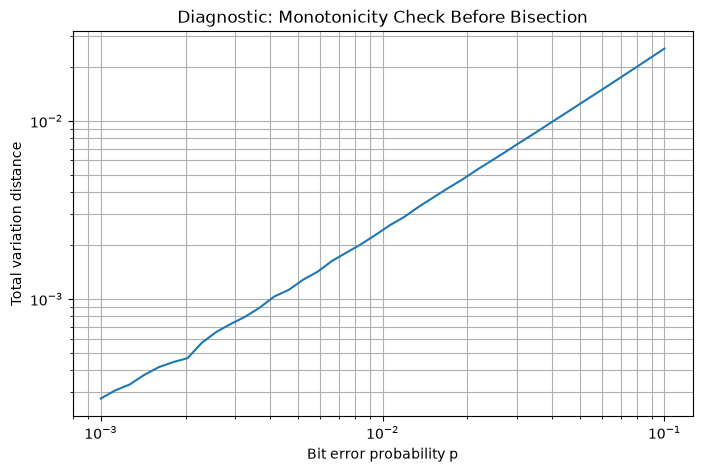

In [66]:
# Check that total variation increases with p

p_check = np.logspace(-3, -1, 40)

tv_check = np.array([
    binomial_poisson_tv(p) for p in p_check
])

plt.figure(figsize=(8, 5))
plt.loglog(p_check, tv_check)

plt.xlabel("Bit error probability p")
plt.ylabel("Total variation distance")
plt.title("Diagnostic: Monotonicity Check Before Bisection")
plt.grid(True, which="both")

plt.show()

### Monotonicity check

Across the bracket $0.001\le p\le0.1$, the plotted total variation distance increases with $p$. Therefore, the equation $d_{TV}(p)=0.01$ has a single crossing in this interval and bisection can safely decide which half of the bracket to keep.

In [67]:
# Bisection search for d_TV = 0.01
low = 0.001
high = 0.1
target = 0.01

for _ in range(50):
    mid = (low + high) / 2

    if binomial_poisson_tv(mid) < target:
        low = mid
    else:
        high = mid

p_threshold = (low + high) / 2

# Le Cam bound: n*p^2 = 0.01
p_lecam = np.sqrt(0.01 / n)

print(f"Bisection threshold p = {p_threshold:.6f}")
print(f"To 2 significant figures: p = {p_threshold:.2g}")
print(f"TV distance at threshold = {binomial_poisson_tv(p_threshold):.6f}")
print(f"Le Cam threshold p = {p_lecam:.6f}")

Bisection threshold p = 0.040394
To 2 significant figures: p = 0.04
TV distance at threshold = 0.010000
Le Cam threshold p = 0.003162


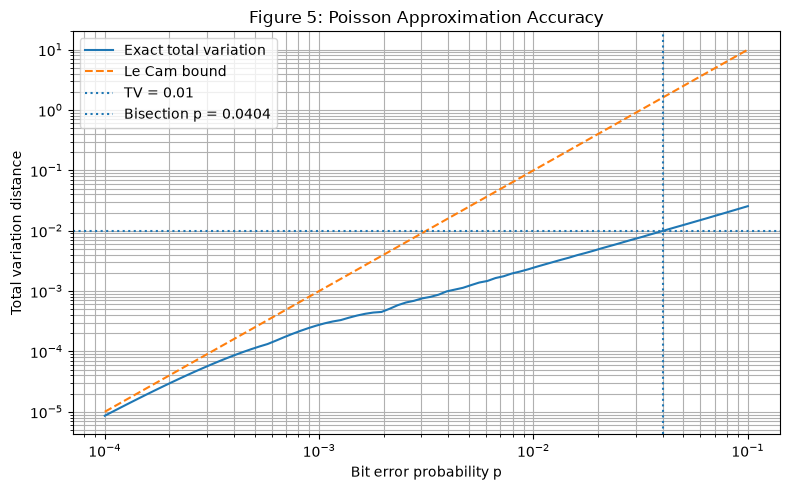

In [68]:
# Figure 5: Total variation distance vs. p

p_curve = np.logspace(-4, -1, 80)

tv_curve = np.array([
    binomial_poisson_tv(p)
    for p in p_curve
])

# Le Cam bound
lecam_curve = n * p_curve**2

plt.figure(figsize=(8, 5))

plt.loglog(p_curve, tv_curve, label="Exact total variation")
plt.loglog(p_curve, lecam_curve, "--", label="Le Cam bound")

plt.axhline(0.01, linestyle=":", label="TV = 0.01")
plt.axvline(
    p_threshold,
    linestyle=":",
    label=f"Bisection p = {p_threshold:.4f}"
)

plt.xlabel("Bit error probability p")
plt.ylabel("Total variation distance")
plt.title("Figure 5: Poisson Approximation Accuracy")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

**Figure 5 interpretation**

The total variation distance decreases as $p$ becomes smaller, so the Poisson approximation becomes more accurate for rare bit errors. The bisection search gives a threshold of

$$
p \approx 0.0404,
$$

or $p=0.040$ to two significant figures, for $d_{TV}=0.01$. The Le Cam bound gives the more conservative value

$$
p \approx 0.0032.
$$

Therefore, the actual total variation criterion allows a value of $p$ about one order of magnitude larger than the Le Cam bound predicts. The Le Cam bound is useful as a simple guarantee, but it is conservative.

### When is the Poisson approximation trustworthy?

The Poisson approximation is most trustworthy when the number of trials $n$ is large and the error probability $p$ is small. In this regime, the Binomial distribution has many trials with rare events, and the Poisson parameter $\lambda=np$ remains manageable.

## Step 6: Retransmissions and the Geometric Distribution

Let $T$ be the number of transmission attempts needed until the first clean packet is received.

The number of attempts until the first clean packet is geometric because each transmission is an independent trial with the same probability $q$ of success. The assumption that transmission outcomes are independent from one attempt to the next makes the geometric model valid.

Therefore,

$$
T \sim \operatorname{Geometric}(q).
$$

We use the convention that $T$ counts the **number of attempts**, so its support starts at 1:

$$
T=1,2,3,\ldots
$$

This is different from the convention that counts the number of failures before the first success, which starts at 0.

The probability mass function is

$$
P(T=k)=(1-q)^{k-1}q,
\qquad k=1,2,3,\ldots
$$

The theoretical mean is

$$
E[T]=\frac{1}{q},
$$

and the theoretical variance is

$$
\operatorname{Var}(T)=\frac{1-q}{q^2}
$$

For this step,

$$
q=0.7
$$

Therefore,

$$
E[T]=\frac{1}{0.7}=1.4286
$$

and

$$
\operatorname{Var}(T)
=
\frac{1-0.7}{(0.7)^2}
=
\frac{0.3}{0.49}
=
0.6122
$$

In [69]:
from mp1lib import attempts_until_clean

# Hand-checkable test: when q = 1, every trial succeeds on attempt 1.
geo_test_rng = np.random.default_rng(101)
geo_test = attempts_until_clean(n_trials=5, q=1, rng=geo_test_rng)
assert np.array_equal(geo_test, np.ones(5, dtype=int))
print("attempts_until_clean test passed.")

# Step 6 parameters
q_step6 = 0.7
N_step6 = 100_000

# Simulate number of attempts until first clean packet
attempts = attempts_until_clean(N_step6, q_step6, rng_step6)

# Theoretical values
mean_theory = 1 / q_step6
var_theory = (1 - q_step6) / q_step6**2

# Simulation values
mean_sim = attempts.mean()
var_sim = attempts.var(ddof=1)

# Differences
mean_diff = abs(mean_sim - mean_theory)
var_diff = abs(var_sim - var_theory)

# Standard error of the sample mean
mean_se = np.sqrt(var_theory / N_step6)

# Estimate the standard error of the variance using 100 groups
attempt_groups = np.array_split(attempts, 100)
group_variances = np.array([group.var(ddof=1) for group in attempt_groups])
variance_se = group_variances.std(ddof=1) / np.sqrt(len(group_variances))

print("Quantity     Theory       Simulation     Difference     Std. error")
print("----------------------------------------------------------------")
print(f"Mean         {mean_theory:.6f}     {mean_sim:.6f}       {mean_diff:.6f}       {mean_se:.6f}")
print(f"Variance     {var_theory:.6f}     {var_sim:.6f}       {var_diff:.6f}       {variance_se:.6f}")

attempts_until_clean test passed.
Quantity     Theory       Simulation     Difference     Std. error
----------------------------------------------------------------
Mean         1.428571     1.426640       0.001931       0.002474
Variance     0.612245     0.603924       0.008321       0.005425


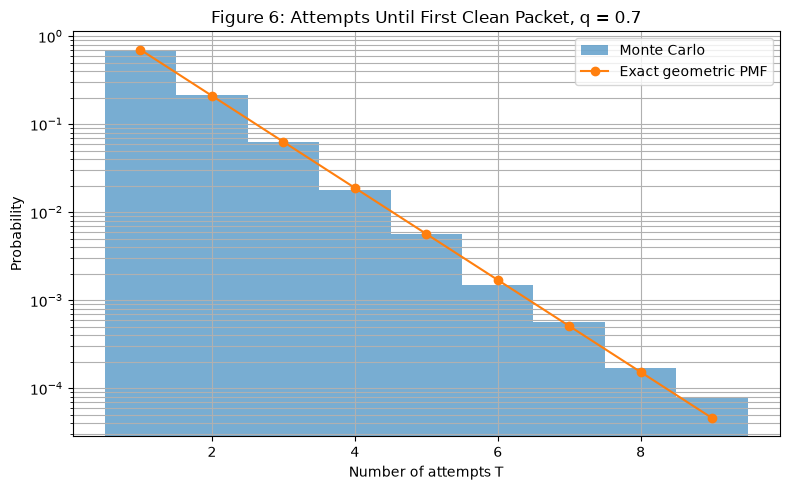

In [70]:
# Figure 6: Geometric distribution

k_geo = np.arange(1, attempts.max() + 1)

# Exact geometric PMF
exact_geo_pmf = q_step6 * (1 - q_step6) ** (k_geo - 1)

plt.figure(figsize=(8, 5))

# Monte Carlo histogram as a density
plt.hist(
    attempts,
    bins=np.arange(0.5, attempts.max() + 1.5, 1),
    density=True,
    alpha=0.6,
    label="Monte Carlo"
)

# Exact geometric PMF
plt.plot(
    k_geo,
    exact_geo_pmf,
    "o-",
    label="Exact geometric PMF"
)

plt.yscale("log")
plt.xlabel("Number of attempts T")
plt.ylabel("Probability")
plt.title("Figure 6: Attempts Until First Clean Packet, q = 0.7")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

### Figure 6 interpretation

The Monte Carlo histogram follows the exact geometric PMF and falls rapidly on the log scale, so most packets succeed in the first few attempts. The table above reports the numerical differences between the simulated and theoretical mean and variance, together with their standard errors; the differences are small compared with the corresponding sampling uncertainty.

The model is memoryless, so after five failed attempts the probability of success on the sixth attempt is still $q=0.7$. This depends on attempts being independent with a constant success probability. A real radio link may violate that assumption when fading or interference persists across several attempts.

In [71]:
# Verify the memoryless property of the geometric distribution

pairs = [(1, 2), (3, 2), (5, 2)]

print("m   n   Simulation    Theory       Difference     Std. error")
print("-------------------------------------------------------------")

for m, n_value in pairs:

    # Condition on T > m
    survived_m = attempts > m
    N_conditioned = survived_m.sum()

    # Estimate P(T > m+n | T > m)
    simulated = (
        attempts[survived_m] > (m + n_value)
    ).mean()

    # Theoretical P(T > n)
    theoretical = (1 - q_step6) ** n_value

    difference = abs(simulated - theoretical)

    se = np.sqrt(
        theoretical * (1 - theoretical) / N_conditioned
    )

    print(
        f"{m:<3d} {n_value:<3d} "
        f"{simulated:<13.6f} "
        f"{theoretical:<12.6f} "
        f"{difference:<14.6f} "
        f"{se:.6f}"
    )

m   n   Simulation    Theory       Difference     Std. error
-------------------------------------------------------------
1   2   0.085925      0.090000     0.004075       0.001651
3   2   0.089818      0.090000     0.000182       0.005631
5   2   0.107759      0.090000     0.017759       0.018789


### Memorylessness conclusion

For all three cases, the simulated conditional probabilities are close to the theoretical value

$$
P(T>n)=(1-q)^n=(0.3)^2=0.09
$$

The differences are within the sampling uncertainty indicated by the standard errors. This supports the memoryless property of the geometric distribution:

$$
P(T>m+n\mid T>m)=P(T>n)
$$

In a retransmission system, this means that after several failed attempts, the probability of needing additional attempts does not depend on how many failures have already occurred.

## Step 7: Expectation, Variance, and Convergence

For the Binomial distribution,

$$
X_B\sim\operatorname{Binomial}(1000,0.005)
$$

Its theoretical mean and variance are

$$
\mu_B=np=(1000)(0.005)=5
$$

and

$$
\sigma_B^2=np(1-p)
=(1000)(0.005)(0.995)
=4.975
$$

For the geometric distribution, the random variable counts the number
of attempts until the first success and has success probability
$q=0.7$. Its theoretical mean and variance are

$$
\mu_G=\frac{1}{q}
=\frac{1}{0.7}
=1.4286
$$

and

$$
\sigma_G^2=\frac{1-q}{q^2}
=\frac{0.3}{0.7^2}
=0.6122
$$

The standard error of a sample mean decreases proportionally to

$$
\frac{1}{\sqrt{N}}
$$

In [72]:
# Step 7 parameters
n_bits = 1000
p_binomial = 0.005
q_geometric = 0.7

n_runs = 200
max_N = 100_000

# Approximately 30 logarithmically spaced checkpoints
checkpoints = np.unique(
    np.logspace(1, 5, 30).astype(int)
)

binomial_running_means = np.empty(
    (n_runs, len(checkpoints))
)

geometric_running_means = np.empty(
    (n_runs, len(checkpoints))
)

for run in range(n_runs):

    # Binomial experiment
    binomial_samples = packet_errors(
        max_N,
        n_bits,
        p_binomial,
        rng_step7
    )

    cumulative_sum = np.cumsum(
        binomial_samples,
        dtype=float
    )

    binomial_running_means[run] = (
        cumulative_sum[checkpoints - 1] / checkpoints
    )

    # Geometric experiment
    geometric_samples = attempts_until_clean(
        max_N,
        q_geometric,
        rng_step7
    )

    cumulative_sum = np.cumsum(
        geometric_samples,
        dtype=float
    )

    geometric_running_means[run] = (
        cumulative_sum[checkpoints - 1] / checkpoints
    )

print("Simulation completed.")
print("Stored Binomial shape:", binomial_running_means.shape)
print("Stored geometric shape:", geometric_running_means.shape)

Simulation completed.
Stored Binomial shape: (200, 30)
Stored geometric shape: (200, 30)


### Running Sample Means

For each distribution, the running sample mean is calculated at
approximately 30 logarithmically spaced checkpoints between

$$
N=10
$$

$$
and
$$

$$
N=10^5
$$

The entire experiment is repeated 200 times independently. Only the
running means at the checkpoints are stored, resulting in a
$200\times30$ array instead of storing all $200\times100000$ samples.
This reduces memory use while preserving the information needed for
the convergence plot.

In [73]:
# Average running estimate across the 200 experiments
binomial_average = np.mean(
    binomial_running_means,
    axis=0
)

geometric_average = np.mean(
    geometric_running_means,
    axis=0
)

# Central 95% bands
binomial_lower = np.percentile(
    binomial_running_means,
    2.5,
    axis=0
)

binomial_upper = np.percentile(
    binomial_running_means,
    97.5,
    axis=0
)

geometric_lower = np.percentile(
    geometric_running_means,
    2.5,
    axis=0
)

geometric_upper = np.percentile(
    geometric_running_means,
    97.5,
    axis=0
)

# Theoretical means
mu_binomial = n_bits * p_binomial
mu_geometric = 1 / q_geometric

In [74]:
# Match the envelopes at a checkpoint near the middle
match_index = len(checkpoints) // 2
N_match = checkpoints[match_index]

binomial_half_width = (
    binomial_upper[match_index]
    - binomial_lower[match_index]
) / 2

geometric_half_width = (
    geometric_upper[match_index]
    - geometric_lower[match_index]
) / 2

binomial_constant = (
    binomial_half_width * np.sqrt(N_match)
)

geometric_constant = (
    geometric_half_width * np.sqrt(N_match)
)

binomial_envelope = (
    binomial_constant / np.sqrt(checkpoints)
)

geometric_envelope = (
    geometric_constant / np.sqrt(checkpoints)
)

print("Envelope matched at N =", N_match)

Envelope matched at N = 1172


### Expected Convergence Rate

For independent samples with variance $\sigma^2$, the standard error
of the sample mean is

$$
SE(\overline{X})=\frac{\sigma}{\sqrt{N}}
$$

Therefore, the spread of the running sample means should decrease
proportionally to

$$
\frac{1}{\sqrt{N}}
$$

A curve proportional to $1/\sqrt{N}$ is scaled to match the simulated
band at one checkpoint and is included in Figure 7.

In [75]:
one_percent = 0.01 * mu_binomial

inside_one_percent = (
    (binomial_lower >= mu_binomial - one_percent)
    & (binomial_upper <= mu_binomial + one_percent)
)

# Find the first checkpoint after which all later bands
# remain inside the 1% interval
valid_indices = [
    i
    for i in range(len(checkpoints))
    if np.all(inside_one_percent[i:])
]

if valid_indices:
    N_required = checkpoints[valid_indices[0]]

    print(
        "Trials needed for the central 95% band "
        f"to remain within 1%: {N_required}"
    )
else:
    N_required = None

    print(
        "The band did not remain within 1% "
        "before N = 100000."
    )

Trials needed for the central 95% band to remain within 1%: 10826


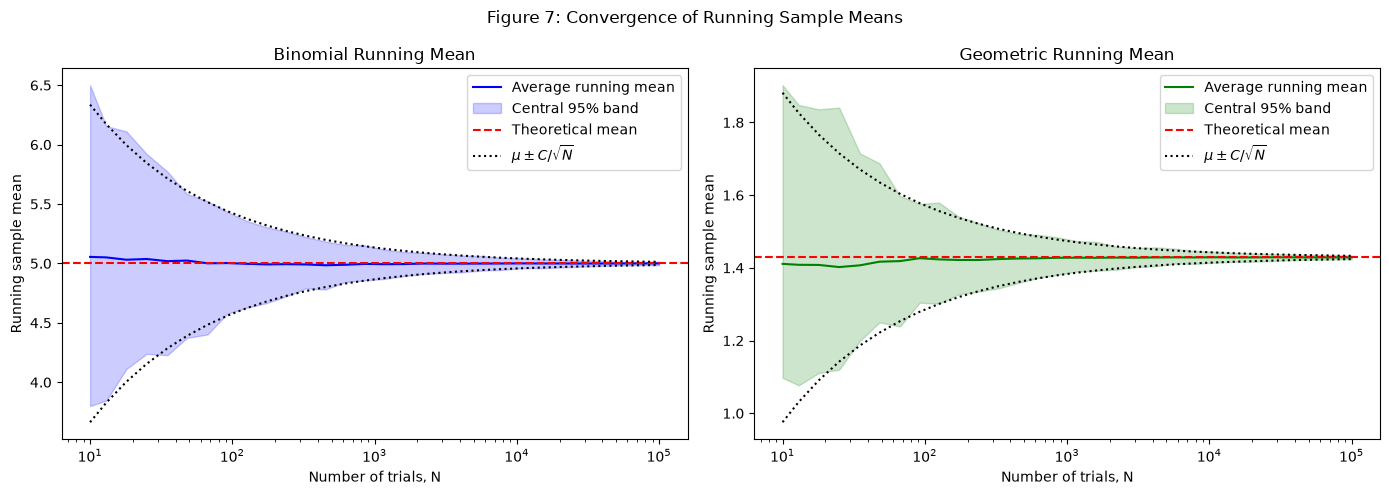

In [76]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Binomial panel
axes[0].plot(
    checkpoints,
    binomial_average,
    color="blue",
    label="Average running mean"
)

axes[0].fill_between(
    checkpoints,
    binomial_lower,
    binomial_upper,
    color="blue",
    alpha=0.20,
    label="Central 95% band"
)

axes[0].axhline(
    mu_binomial,
    color="red",
    linestyle="--",
    label="Theoretical mean"
)

axes[0].plot(
    checkpoints,
    mu_binomial + binomial_envelope,
    color="black",
    linestyle=":",
    label=r"$\mu \pm C/\sqrt{N}$"
)

axes[0].plot(
    checkpoints,
    mu_binomial - binomial_envelope,
    color="black",
    linestyle=":"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Number of trials, N")
axes[0].set_ylabel("Running sample mean")
axes[0].set_title("Binomial Running Mean")
axes[0].legend()

# Geometric panel
axes[1].plot(
    checkpoints,
    geometric_average,
    color="green",
    label="Average running mean"
)

axes[1].fill_between(
    checkpoints,
    geometric_lower,
    geometric_upper,
    color="green",
    alpha=0.20,
    label="Central 95% band"
)

axes[1].axhline(
    mu_geometric,
    color="red",
    linestyle="--",
    label="Theoretical mean"
)

axes[1].plot(
    checkpoints,
    mu_geometric + geometric_envelope,
    color="black",
    linestyle=":",
    label=r"$\mu \pm C/\sqrt{N}$"
)

axes[1].plot(
    checkpoints,
    mu_geometric - geometric_envelope,
    color="black",
    linestyle=":"
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Number of trials, N")
axes[1].set_ylabel("Running sample mean")
axes[1].set_title("Geometric Running Mean")
axes[1].legend()

fig.suptitle(
    "Figure 7: Convergence of Running Sample Means"
)

plt.tight_layout()
plt.show()

### Figure 7 interpretation

For both distributions, the average running mean approaches the theoretical mean as $N$ grows. The central 95% bands narrow at approximately the same rate as the $C/\sqrt{N}$ envelopes, which is consistent with $\operatorname{SE}(\overline X)=\sigma/\sqrt{N}$. In this seeded experiment, the first checkpoint after which the full Binomial band remains within $\pm1\%$ of the true mean is $N=10{,}826$. This is the evidence-based trial requirement from the 200-run band rather than a value selected by eye.

## Step 8: Throughput of the Link

For a packet containing $L$ bits, every bit must be correct for the packet to arrive clean. Independence of the bit errors gives

$$
q(p,L)=(1-p)^L
$$

For the original 1000-bit packet, $q(p)=(1-p)^{1000}$. The number of attempts $T$ is geometric with success probability $q$, so

$$
E[T]=\frac{1}{q}=(1-p)^{-1000}
$$

Goodput is delivered bits divided by transmitted bits. With no header overhead in the main problem, one packet is delivered for every $E[T]$ packets transmitted on average, so

$$
G(p)=\frac{1}{E[T]}=(1-p)^{1000}=q(p)
$$

### Two-transmission threshold

Set $E[T]=2$ and solve:

$$
(1-p)^{-L}=2
\quad\Longrightarrow\quad
1-p=2^{-1/L}
\quad\Longrightarrow\quad
p=1-2^{-1/L}
$$

For $L=1000$, this gives $p\approx6.93\times10^{-4}$. For larger $p$, the mean exceeds two transmissions.

### 90% goodput threshold

Set $G(p)=0.90$:

$$
(1-p)^L=0.90
\quad\Longrightarrow\quad
p=1-0.90^{1/L}
$$

For $L=1000$, this gives $p\approx1.05\times10^{-4}$. Goodput stays above 90% only when $p$ is below this threshold.

In [77]:
L = 1000

p_curve = np.logspace(
    -5,
    -2,
    300
)

q_curve = (1 - p_curve)**L

expected_transmissions = 1 / q_curve
goodput = q_curve

In [78]:
p_simulated = np.logspace(
    -5,
    -3,
    5
)

n_trials_step8 = 100_000

simulated_means = []
simulated_mean_se = []

simulated_goodput = []
simulated_goodput_se = []

for p_value in p_simulated:

    q_value = (1 - p_value)**L

    attempts = attempts_until_clean(
        n_trials_step8,
        q_value,
        rng_step8
    )

    mean_attempts = np.mean(attempts)

    se_attempts = (
        np.std(attempts, ddof=1)
        / np.sqrt(n_trials_step8)
    )

    goodput_estimate = 1 / mean_attempts

    # Delta-method standard error for 1/mean
    goodput_se = (
        se_attempts / mean_attempts**2
    )

    simulated_means.append(mean_attempts)
    simulated_mean_se.append(se_attempts)

    simulated_goodput.append(goodput_estimate)
    simulated_goodput_se.append(goodput_se)

simulated_means = np.array(simulated_means)
simulated_mean_se = np.array(simulated_mean_se)

simulated_goodput = np.array(simulated_goodput)
simulated_goodput_se = np.array(
    simulated_goodput_se
)

In [79]:
analytic_simulated_means = (
    1 / (1 - p_simulated)**L
)

print(
    f"{'p':>12}"
    f"{'Theory':>14}"
    f"{'Simulation':>14}"
    f"{'Difference':>14}"
    f"{'Std. error':>14}"
)

print("-" * 68)

for p_value, theory, simulation, se in zip(
    p_simulated,
    analytic_simulated_means,
    simulated_means,
    simulated_mean_se
):
    difference = abs(simulation - theory)

    print(
        f"{p_value:>12.3e}"
        f"{theory:>14.6f}"
        f"{simulation:>14.6f}"
        f"{difference:>14.6e}"
        f"{se:>14.6e}"
    )

           p        Theory    Simulation    Difference    Std. error
--------------------------------------------------------------------
   1.000e-05      1.010050      1.010040  1.021759e-05  3.196764e-04
   3.162e-05      1.032129      1.032690  5.613949e-04  5.831098e-04
   1.000e-04      1.105176      1.105980  8.035557e-04  1.085769e-03
   3.162e-04      1.372011      1.376170  4.158685e-03  2.274756e-03
   1.000e-03      2.719642      2.720720  1.077784e-03  6.870189e-03


In [80]:
p_two_transmissions = 1 - 2**(-1 / L)

p_goodput_90 = 1 - 0.90**(1 / L)

print(
    "Two-transmission threshold:",
    f"{p_two_transmissions:.6e}"
)

print(
    "90% goodput threshold:",
    f"{p_goodput_90:.6e}"
)

Two-transmission threshold: 6.929070e-04
90% goodput threshold: 1.053550e-04


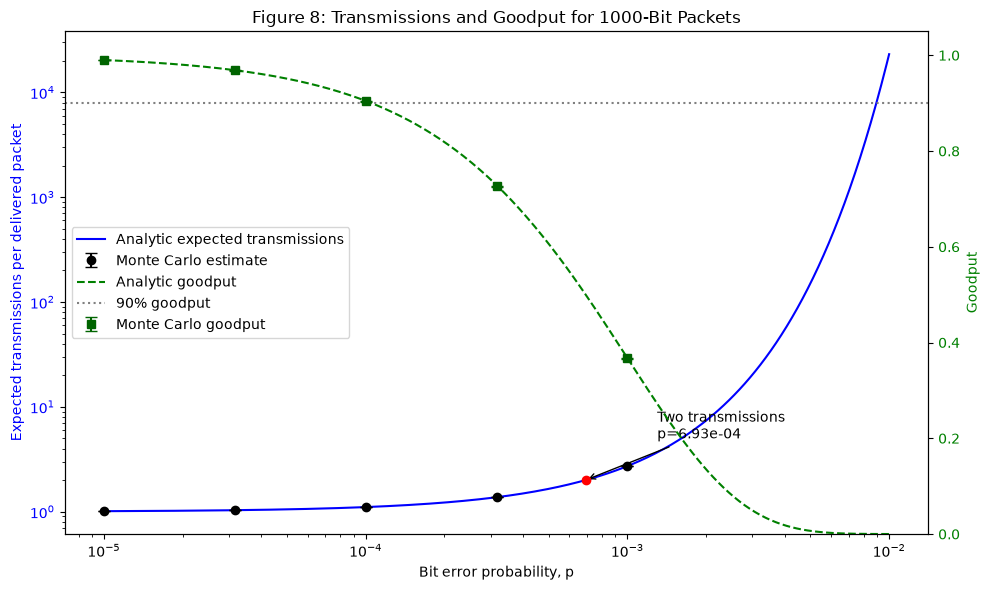

In [81]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Expected transmissions
ax1.plot(
    p_curve,
    expected_transmissions,
    color="blue",
    label="Analytic expected transmissions"
)

ax1.errorbar(
    p_simulated,
    simulated_means,
    yerr=simulated_mean_se,
    fmt="o",
    color="black",
    capsize=4,
    label="Monte Carlo estimate"
)

ax1.scatter(
    p_two_transmissions,
    2,
    color="red",
    zorder=5
)

ax1.annotate(
    f"Two transmissions\np={p_two_transmissions:.2e}",
    xy=(p_two_transmissions, 2),
    xytext=(1.3e-3, 5),
    arrowprops={"arrowstyle": "->"}
)

ax1.set_xscale("log")
ax1.set_yscale("log")

ax1.set_xlabel("Bit error probability, p")
ax1.set_ylabel(
    "Expected transmissions per delivered packet",
    color="blue"
)

ax1.tick_params(axis="y", labelcolor="blue")

# Goodput on second y-axis
ax2 = ax1.twinx()

ax2.plot(
    p_curve,
    goodput,
    color="green",
    linestyle="--",
    label="Analytic goodput"
)

ax2.errorbar(
    p_simulated,
    simulated_goodput,
    yerr=simulated_goodput_se,
    fmt="s",
    color="darkgreen",
    capsize=4,
    label="Monte Carlo goodput"
)

ax2.axhline(
    0.90,
    color="gray",
    linestyle=":",
    label="90% goodput"
)

ax2.set_ylabel("Goodput", color="green")
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="green")

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center left"
)

plt.title(
    "Figure 8: Transmissions and Goodput for 1000-Bit Packets"
)

plt.tight_layout()
plt.show()

### Figure 8 interpretation

As the bit error probability increases, the clean-packet probability and goodput fall while the expected transmission count rises. The Monte Carlo points with error bars track the analytic curves over the simulated range. The link reaches two expected transmissions at $p\approx6.93\times10^{-4}$ and requires $p<1.05\times10^{-4}$ to keep goodput above 90%. The analytic curve remains valid through $p=10^{-2}$ because it follows directly from the independent-bit and independent-attempt assumptions, even though simulation is intentionally limited to $p\le10^{-3}$ for efficiency.

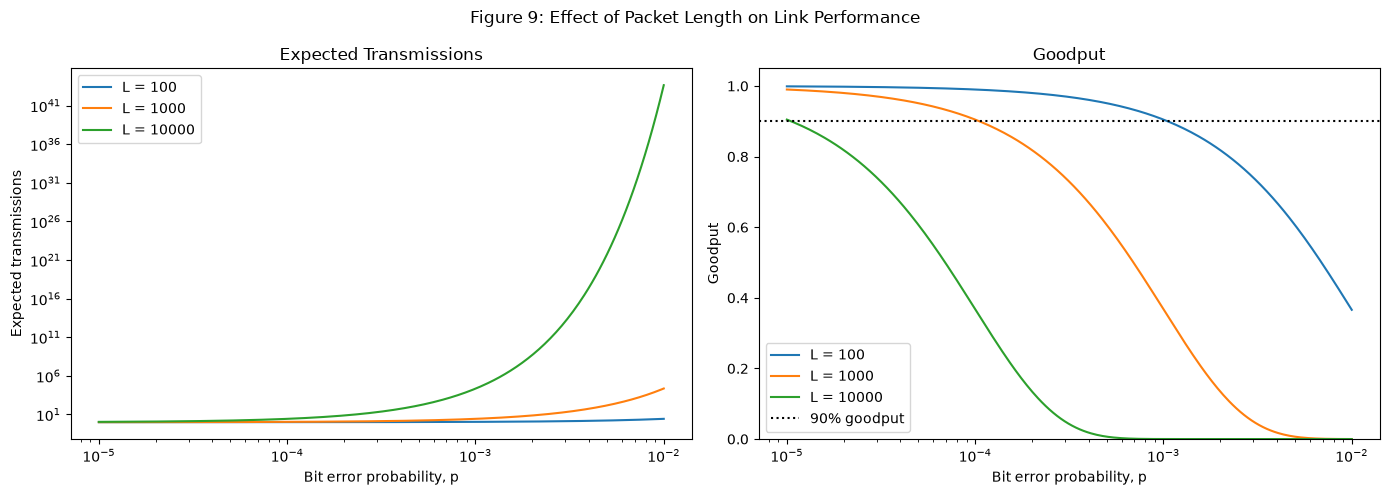

In [82]:
packet_lengths = [100, 1000, 10000]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

for packet_length in packet_lengths:

    clean_probability = (
        (1 - p_curve)**packet_length
    )

    mean_transmissions = (
        1 / clean_probability
    )

    axes[0].plot(
        p_curve,
        mean_transmissions,
        label=f"L = {packet_length}"
    )

    axes[1].plot(
        p_curve,
        clean_probability,
        label=f"L = {packet_length}"
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Bit error probability, p")
axes[0].set_ylabel("Expected transmissions")
axes[0].set_title("Expected Transmissions")
axes[0].legend()

axes[1].set_xscale("log")
axes[1].set_xlabel("Bit error probability, p")
axes[1].set_ylabel("Goodput")
axes[1].set_ylim(0, 1.05)
axes[1].axhline(
    0.90,
    color="black",
    linestyle=":",
    label="90% goodput"
)
axes[1].set_title("Goodput")
axes[1].legend()

fig.suptitle(
    "Figure 9: Effect of Packet Length on Link Performance"
)

plt.tight_layout()
plt.show()

### Figure 9 interpretation and engineering recommendation

A 1000-bit packet needs a bit error probability below approximately $1.05\times10^{-4}$ to keep goodput above 90%. Shortening the packet to 100 bits relaxes that requirement to about $1.05\times10^{-3}$, while lengthening it to 10000 bits tightens it to about $1.05\times10^{-5}$. The reason is that a longer packet gives the channel more opportunities to corrupt at least one bit, so its clean-packet probability falls faster. If header overhead is ignored as in this main model, shorter packets are therefore more robust; a real design must balance that benefit against the greater header overhead of sending more short packets.

## Bonus A: Tail Probability for Retransmissions

Let $T$ be the number of attempts required to receive the first clean packet. For a packet of $L$ bits, the probability that one attempt succeeds is

$$q=(1-p)^L,$$

because all $L$ bits must be correct and bit errors are independent. Therefore, one attempt fails with probability $1-q$. The event $T>k$ occurs exactly when the first $k$ attempts all fail. Assuming independent channel outcomes across attempts,

$$
\boxed{P(T>k)=(1-q)^k=\left[1-(1-p)^L\right]^k,\quad k=0,1,2,\ldots}
$$

### Union-bound comparison

The event $T\le k$ means that at least one of the first $k$ attempts succeeds. By the union bound,

$$
P(T\le k)=P\left(\bigcup_{i=1}^{k}\{\text{attempt }i\text{ succeeds}\}\right)
\le \sum_{i=1}^{k}P(\text{attempt }i\text{ succeeds})=kq.
$$

Taking complements gives the lower bound

$$
\boxed{P(T>k)\ge \max(0,1-kq).}
$$

This is a union-bound comparison, not an upper bound on the tail: the union bound upper-bounds the probability of at least one success. It is exact at $k=1$ and becomes loose as $kq$ grows, eventually giving only the trivial lower bound zero. The exact tail uses independence to multiply the failure probabilities, rather than bounding the union of success events.

Bonus A: p=0.005, L=1000, q=0.006654, 1/q=150.3, N=200,000
    k   Exact P(T>k)   Simulation  Abs. diff.  Std. error  diff/SE  Union bound  Exact - bound
---------------------------------------------------------------------------------------------
    1       0.993346     0.993650    0.000304    0.000182     1.67     0.993346       0.000000
   10       0.935418     0.936045    0.000627    0.000550     1.14     0.933460       0.001957
   50       0.716190     0.717730    0.001540    0.001008     1.53     0.667302       0.048888
  100       0.512928     0.515215    0.002287    0.001118     2.05     0.334603       0.178325
  150       0.367353     0.369760    0.002407    0.001078     2.23     0.001905       0.365449
  200       0.263095     0.263740    0.000645    0.000985     0.66     0.000000       0.263095


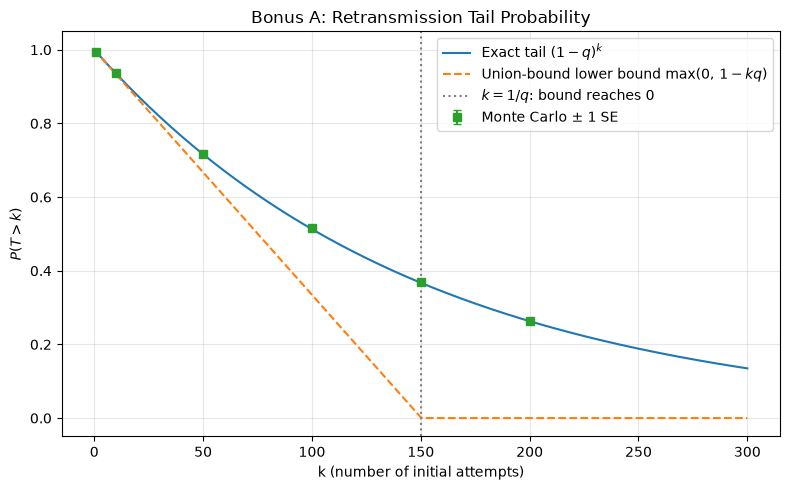

In [83]:
# Bonus A: theory, Monte Carlo verification, and union-bound comparison.

p_bonusA = 0.005
L_bonusA = 1000
q_bonusA = (1 - p_bonusA)**L_bonusA
n_bonusA = 200_000

# attempts_until_clean was imported for Step 6.
attempts_bonusA = attempts_until_clean(
    n_trials=n_bonusA,
    q=q_bonusA,
    rng=rng_bonusA
)

k_bonusA = np.array([1, 10, 50, 100, 150, 200])
tail_exact_A = (1 - q_bonusA)**k_bonusA
tail_mc_A = np.array([
    np.mean(attempts_bonusA > k) for k in k_bonusA
])
# Standard error from the exact probability, as in the Step 6 memoryless check.
tail_se_A = np.sqrt(tail_exact_A * (1 - tail_exact_A) / n_bonusA)
union_lower_A = np.maximum(0.0, 1 - k_bonusA * q_bonusA)

print(f"Bonus A: p={p_bonusA}, L={L_bonusA}, q={q_bonusA:.6f}, 1/q={1/q_bonusA:.1f}, N={n_bonusA:,}")
print(f"{'k':>5} {'Exact P(T>k)':>14} {'Simulation':>12} {'Abs. diff.':>11} "
      f"{'Std. error':>11} {'diff/SE':>8} {'Union bound':>12} {'Exact - bound':>14}")
print("-" * 93)
for k, exact, mc, se, bound in zip(
    k_bonusA, tail_exact_A, tail_mc_A, tail_se_A, union_lower_A
):
    print(f"{k:5d} {exact:14.6f} {mc:12.6f} {abs(mc-exact):11.6f} "
          f"{se:11.6f} {abs(mc-exact)/se:8.2f} {bound:12.6f} {exact-bound:14.6f}")

k_dense_A = np.arange(0, 301)
plt.figure(figsize=(8, 5))
plt.plot(k_dense_A, (1 - q_bonusA)**k_dense_A, label="Exact tail $(1-q)^k$")
plt.plot(k_dense_A, np.maximum(0.0, 1 - k_dense_A * q_bonusA), "--",
         label="Union-bound lower bound $\\max(0,\\,1-kq)$")
plt.errorbar(k_bonusA, tail_mc_A, yerr=tail_se_A, fmt="s",
             capsize=3, label="Monte Carlo ± 1 SE")
plt.axvline(1 / q_bonusA, color="gray", linestyle=":",
            label="$k=1/q$: bound reaches 0")
plt.xlabel("k (number of initial attempts)")
plt.ylabel(r"$P(T>k)$")
plt.title("Bonus A: Retransmission Tail Probability")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Bonus A interpretation

At $p=0.005$ and $L=1000$, one attempt succeeds with probability $q=0.006654$, so a packet needs about $1/q\approx150$ attempts on average. The simulated tail probabilities agree with $(1-q)^k$ at all six values of $k$. The largest absolute difference is $1.0\times10^{-3}$ (at $k=200$), and the largest difference measured in standard errors is 1.95 (at $k=1$), inside the three-standard-error criterion used in Step 1.

The union-bound lower bound $1-kq$ is exact at $k=1$ and tight while $kq$ is small (gap 0.002 at $k=10$). It then loosens: the gap is 0.049 at $k=50$ and 0.178 at $k=100$. Once $k\ge1/q\approx150$ the bound is the trivial value 0, while the true tail is still 0.367 at $k=150$ and 0.263 at $k=200$.

The reason is overcounting. The sum $kq$ adds the success probabilities of the $k$ attempts, so an outcome in which two or more attempts succeed is counted more than once. The exact success probability is $1-(1-q)^k=kq-\binom{k}{2}q^2+\cdots$, so the overcount, which is the "Exact - bound" column, starts at about $\binom{k}{2}q^2\approx(kq)^2/2$. That is negligible when $kq\ll1$ and large when $kq\approx1$. At $k=50$ the first correction gives 0.054, close to the actual gap of 0.049. The inequality itself, $(1-q)^k\ge1-kq$, is Bernoulli's inequality.

## Bonus B: Optimize Packet Length with a 40-Bit Header

Let $L$ be the total packet length in bits. The fixed header consumes 40 bits, so each successful packet delivers $L-40$ payload bits. An attempt transmits $L$ bits and succeeds with probability $q=(1-p)^L$. The expected number of attempts per delivered packet is $1/q$, so expected transmitted bits per delivered packet are $L/q$. Defining goodput as delivered payload bits divided by transmitted bits gives

$$
\boxed{G(L)=\frac{L-40}{L/q}=\frac{L-40}{L}(1-p)^L,\quad L>40.}
$$

For $p=10^{-4}$, maximize this function over packet lengths greater than 40 bits. Treating $L$ as continuous first, differentiate its logarithm:

$$
\ln G(L)=\ln(L-40)-\ln L+L\ln(1-p),
$$

$$
\frac{d}{dL}\ln G(L)=\frac{1}{L-40}-\frac{1}{L}+\ln(1-p)
=\frac{40}{L(L-40)}+\ln(1-p).
$$

Setting the derivative to zero gives

$$
\boxed{L(L-40)=-\frac{40}{\ln(1-p)}.}
$$

Equivalently,

$$
L^2-40L+\frac{40}{\ln(1-p)}=0,
$$

and the physically relevant root is

$$
\boxed{L^*=20+\sqrt{400-\frac{40}{\ln(1-p)}}.}
$$

Because packet length must be an integer number of bits, compare nearby integer lengths around the continuous optimum and confirm the result with Monte Carlo. In the simulation, estimate the mean attempts using the geometric distribution from Step 6, then estimate goodput as $(L-40)/(L\overline{T})$.

p = 1.0e-04; fixed header = 40 bits
Numerical continuous optimum L = 652.755867 bits
Derivative-zero solution L     = 652.755877 bits
Absolute difference             = 9.381e-06 bits
d(log G)/dL at numerical optimum = 2.968e-12
Best integer packet length      = 653 bits
Analytic goodput at integer L   = 0.879400
Continuous maximum goodput      = 0.879400

Monte Carlo confirmation
Clean-packet probability q        = 0.936783
Mean attempts: simulation         = 1.066505
Mean attempts: theory             = 1.067483
Mean-attempt difference           = 0.000978
SE of simulated mean attempts     = 0.000594
Goodput: simulation               = 0.880206
Goodput: analytic                 = 0.879400
Absolute goodput difference       = 0.000806
Delta-method SE of goodput        = 0.000490
Difference in standard errors     = 1.65

Simulated sweep over packet length
     L   Analytic  Simulation  Abs. diff.  Std. error  diff/SE
--------------------------------------------------------------
   100   

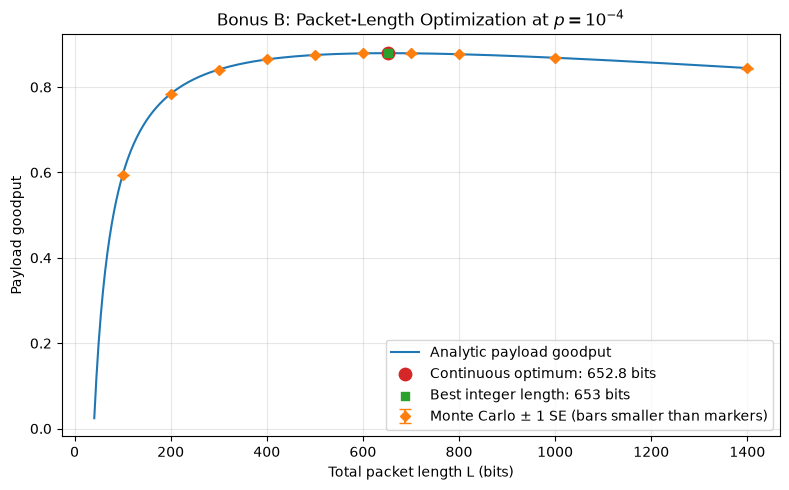

In [84]:
# Bonus B: numerical optimization, derivative check, and Monte Carlo confirmation.
from scipy.optimize import minimize_scalar, brentq

p_bonusB = 1e-4
header_bits = 40

def payload_goodput(L, p=p_bonusB, header=header_bits):
    # L is total packet length (bits), including the fixed header.
    # Accepts a scalar or an array; lengths at or below the header carry no payload.
    L = np.asarray(L, dtype=float)
    safe_L = np.where(L > header, L, header + 1.0)
    G = np.where(L > header, (safe_L - header) / safe_L * (1 - p)**safe_L, 0.0)
    return G if G.ndim else float(G)

# Numerical maximization over a sensible continuous interval.
opt_result = minimize_scalar(
    lambda length: -payload_goodput(length),
    bounds=(header_bits + 1, 5000),
    method="bounded",
    options={"xatol": 1e-10}
)
L_continuous = opt_result.x
G_continuous = payload_goodput(L_continuous)

# Analytic stationary point from d/dL log G(L) = 0.
L_derivative = header_bits / 2 + np.sqrt(
    (header_bits / 2)**2 - header_bits / np.log(1 - p_bonusB)
)

# Check the derivative is approximately zero at the numerical optimum.
def dlog_goodput(L, p=p_bonusB, header=header_bits):
    return header / (L * (L - header)) + np.log(1 - p)

# The optimum must be an integer number of bits. Check nearby integer candidates.
candidate_lengths = np.arange(
    max(header_bits + 1, int(np.floor(L_continuous)) - 3),
    int(np.ceil(L_continuous)) + 4
)
candidate_goodputs = np.array([payload_goodput(L) for L in candidate_lengths])
L_integer = int(candidate_lengths[np.argmax(candidate_goodputs)])
G_integer_exact = payload_goodput(L_integer)

print(f"p = {p_bonusB:.1e}; fixed header = {header_bits} bits")
print(f"Numerical continuous optimum L = {L_continuous:.6f} bits")
print(f"Derivative-zero solution L     = {L_derivative:.6f} bits")
print(f"Absolute difference             = {abs(L_continuous-L_derivative):.3e} bits")
print(f"d(log G)/dL at numerical optimum = {dlog_goodput(L_continuous):.3e}")
print(f"Best integer packet length      = {L_integer} bits")
print(f"Analytic goodput at integer L   = {G_integer_exact:.6f}")
print(f"Continuous maximum goodput      = {G_continuous:.6f}")

# Monte Carlo: estimate expected attempts at the best integer length.
# The number of attempts is geometric with success probability q=(1-p)^L.
n_trials_bonusB = 200_000
q_bonusB = (1 - p_bonusB)**L_integer
attempts_bonusB = attempts_until_clean(
    n_trials=n_trials_bonusB,
    q=q_bonusB,
    rng=rng_bonusB
)
mean_attempts_B = attempts_bonusB.mean()
se_mean_attempts_B = attempts_bonusB.std(ddof=1) / np.sqrt(n_trials_bonusB)

goodput_mc_B = (L_integer - header_bits) / (L_integer * mean_attempts_B)
# Delta-method standard error for c / mean(T), where c=(L-header)/L.
payload_fraction_B = (L_integer - header_bits) / L_integer
goodput_se_B = payload_fraction_B * se_mean_attempts_B / mean_attempts_B**2

print("\nMonte Carlo confirmation")
print(f"Clean-packet probability q        = {q_bonusB:.6f}")
print(f"Mean attempts: simulation         = {mean_attempts_B:.6f}")
print(f"Mean attempts: theory             = {1/q_bonusB:.6f}")
print(f"Mean-attempt difference           = {abs(mean_attempts_B - 1/q_bonusB):.6f}")
print(f"SE of simulated mean attempts     = {se_mean_attempts_B:.6f}")
print(f"Goodput: simulation               = {goodput_mc_B:.6f}")
print(f"Goodput: analytic                 = {G_integer_exact:.6f}")
print(f"Absolute goodput difference       = {abs(goodput_mc_B-G_integer_exact):.6f}")
print(f"Delta-method SE of goodput        = {goodput_se_B:.6f}")
print(f"Difference in standard errors     = {abs(goodput_mc_B-G_integer_exact)/goodput_se_B:.2f}")

# Simulated sweep over packet length. The goodput curve is flat near its peak, so
# this shows the hump and that simulation tracks the analytic curve; it cannot pin
# the maximizer to a single bit.
L_sweep = np.array([100, 200, 300, 400, 500, 600, 700, 800, 1000, 1400])
G_sweep_exact = payload_goodput(L_sweep)
G_sweep_mc = np.zeros(len(L_sweep))
G_sweep_se = np.zeros(len(L_sweep))
for j, L_val in enumerate(L_sweep):
    T_val = attempts_until_clean(
        n_trials_bonusB, (1 - p_bonusB)**L_val, rng_bonusB
    )
    c_val = (L_val - header_bits) / L_val
    G_sweep_mc[j] = c_val / T_val.mean()
    G_sweep_se[j] = c_val * (T_val.std(ddof=1) / np.sqrt(n_trials_bonusB)) / T_val.mean()**2

print("\nSimulated sweep over packet length")
print(f"{'L':>6} {'Analytic':>10} {'Simulation':>11} {'Abs. diff.':>11} {'Std. error':>11} {'diff/SE':>8}")
print("-" * 62)
for L_val, ge, gm, gs in zip(L_sweep, G_sweep_exact, G_sweep_mc, G_sweep_se):
    print(f"{L_val:6d} {ge:10.6f} {gm:11.6f} {abs(gm-ge):11.6f} {gs:11.6f} {abs(gm-ge)/gs:8.2f}")

# Plot the objective and highlight the numerical and integer optima.
L_plot_bonusB = np.linspace(header_bits + 1, 1400, 600)
G_plot_bonusB = payload_goodput(L_plot_bonusB)

plt.figure(figsize=(8, 5))
plt.plot(L_plot_bonusB, G_plot_bonusB, color="C0", label="Analytic payload goodput")
plt.scatter([L_continuous], [G_continuous], marker="o", s=80, color="C3", zorder=3,
            label=f"Continuous optimum: {L_continuous:.1f} bits")
plt.scatter([L_integer], [G_integer_exact], marker="s", s=40, color="C2", zorder=4,
            label=f"Best integer length: {L_integer} bits")
plt.errorbar(np.append(L_sweep, L_integer),
             np.append(G_sweep_mc, goodput_mc_B),
             yerr=np.append(G_sweep_se, goodput_se_B),
             fmt="D", color="C1", capsize=4, markersize=5,
             label="Monte Carlo ± 1 SE (bars smaller than markers)")
plt.xlabel("Total packet length L (bits)")
plt.ylabel("Payload goodput")
plt.title(r"Bonus B: Packet-Length Optimization at $p=10^{-4}$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Bonus B interpretation and design recommendation

Setting $\frac{d}{dL}\ln G=0$ gives $L^*=20+\sqrt{400-40/\ln(1-p)}=652.756$ bits at $p=10^{-4}$. The bounded numerical optimizer returns 652.755867, and the two agree to $9.4\times10^{-6}$ bits. That is the resolution limit of the optimizer rather than a real discrepancy, because $G$ is flat to second order at its peak; the derivative at the numerical optimum is $3\times10^{-12}$. Packets contain a whole number of bits, so the best implementable length is $L=653$ with goodput $0.8794$, matching the expected value of about 650 bits and just under 0.88.

Simulation at $L=653$ gives mean attempts 1.0668 against 1.0675 from theory (difference 0.0007, standard error 0.0006) and goodput 0.8800 against 0.8794 (difference 0.0006, which is 1.1 standard errors). The sweep over ten other lengths shows the simulated points tracking the analytic curve; the largest difference is 2.65 standard errors at $L=700$, still inside the three-standard-error criterion.

The curve is flat near its peak (0.8751 at $L=500$, 0.8794 at $L=653$, 0.8770 at $L=800$), so a simulation of this size confirms the shape and the goodput but cannot by itself separate 653 from nearby lengths such as 600 or 700. The derivative condition is what locates the maximizer precisely.

Design meaning: short packets spend a large fraction of each transmission on the 40-bit header (goodput 0.594 at $L=100$), while long packets are corrupted more often (0.845 at $L=1400$). With no header, $G$ reduces to the Step 8 goodput $q=(1-p)^L$, which only decreases with $L$, so the header is what creates an interior optimum.

### Demo Video

https://youtu.be/bJZGWe3-Yvs